<a href="https://colab.research.google.com/github/knight19720208ui/AI/blob/main/2_NoSupervisado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizaje No Supervisado:

**Algoritmos no supervisados más usados**


| # | Algoritmo | Python puro | scikit-learn |
|---|-----------|:-----------:|:------------:|
| 1 | K-Means | sí | sí (Iris) |
| 2 | PCA | sí | sí (Digits) |
| 3 | Clustering Jerárquico | sí | sí (Iris) |
| 4 | DBSCAN | sí | sí (Iris) |
| 5 | GMM | sí | sí (Iris) |

## Concepto general

El aprendizaje **no supervisado** trabaja solo con **X** (sin etiquetas y). El objetivo es descubrir estructura oculta: grupos, dimensiones relevantes, anomalías.

- **Clustering**: agrupar muestras similares (K-Means, Jerárquico, DBSCAN, GMM).
- **Reducción de dimensionalidad**: proyectar datos de alta dimensión a menor (PCA).


## Configuración inicial

Ejecuten la siguiente celda **antes de empezar**. Instala las librerías necesarias y carga todos los imports que se usarán a lo largo del cuaderno:
- **numpy**: cálculo numérico y generación de datos sintéticos.
- **matplotlib** + **matplotlib.animation**: gráficas estáticas y animaciones.
- **plotly**: gráficas interactivas (especialmente útiles en Colab).
- **pandas**: manipulación de datasets.
- **scikit-learn**: modelos de machine learning y datasets reales.
- **scipy**: distribuciones estadísticas (usado en GMM y clustering jerárquico).
- **IPython.display**: para mostrar animaciones dentro del cuaderno.


In [1]:
# === Instalación de dependencias ===
# En Colab la mayoría ya están instaladas; esto es por seguridad
import sys, subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                       "numpy", "matplotlib", "plotly", "pandas",
                       "scikit-learn", "scipy"])

# === Imports globales ===
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib import rc
from matplotlib.patches import Ellipse
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd
from IPython.display import HTML, display
import warnings
warnings.filterwarnings('ignore')

# Imports específicos de scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.decomposition import PCA as SkPCA

# Imports de scipy
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.stats import multivariate_normal
import matplotlib.patches as mpatches

# Configuración de matplotlib para animaciones en Colab/Jupyter
rc('animation', html='jshtml')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

# Reproducibilidad
np.random.seed(42)

# Verificación
print("Entorno listo. Versiones:")
print(f"  NumPy:        {np.__version__}")
print(f"  Pandas:       {pd.__version__}")
print(f"  Matplotlib:   {__import__('matplotlib').__version__}")
print(f"  Plotly:       {__import__('plotly').__version__}")
import scipy, sklearn
print(f"  scipy:        {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")


Entorno listo. Versiones:
  NumPy:        2.4.6
  Pandas:       2.2.3
  Matplotlib:   3.10.0
  Plotly:       5.24.1
  scipy:        1.16.3
  scikit-learn: 1.6.1


# Glosario de métricas para aprendizaje no supervisado

Antes de los ejemplos, definimos las métricas que se usarán. Cada una aparece **una sola vez** aquí.

## Para clustering

- **Inercia (SSE - Sum of Squared Errors)**: suma de las distancias al cuadrado de cada punto a su centroide. Es la función que K-Means minimiza.
  $$\text{Inercia} = \sum_{i=1}^{n} \min_k \|x_i - \mu_k\|^2$$
  Menor es mejor, pero disminuye monótonamente con K (por eso el "método del codo" para elegir K).

- **Silhouette (coeficiente de silueta)**: mide cuánto se parece un punto a su propio cluster vs al cluster vecino más cercano.
  $$s_i = \frac{b_i - a_i}{\max(a_i, b_i)}$$
  donde $a_i$ = distancia media intra-cluster (a sus vecinos del mismo cluster), $b_i$ = distancia media al cluster más cercano distinto. Rango $[-1, 1]$. $s \approx 1$ punto bien clasificado; $s \approx 0$ en frontera; $s < 0$ mal clasificado.

- **ARI (Adjusted Rand Index)**: compara dos particiones (la del clustering vs las etiquetas verdaderas) corrigiendo por azar. Rango $[-1, 1]$. $ARI=1$ coincidencia perfecta, $ARI=0$ azar, $ARI<0$ peor que azar. Útil cuando tenemos etiquetas verdaderas para evaluar (aunque el clustering no las haya usado).

## Para reducción de dimensionalidad

- **Varianza explicada**: para PCA, la proporción de la varianza total de los datos que captura cada componente principal.
  $$\text{var}_k = \frac{\lambda_k}{\sum_j \lambda_j}$$
  donde $\lambda_k$ es el k-ésimo autovalor. Se acumula para decidir cuántas componentes conservar (típicamente >= 90%).

## Para modelos probabilísticos (GMM)

- **Log-likelihood**: logaritmo de la verosimilitud de los datos bajo el modelo. Mayor (menos negativo) es mejor.

- **BIC (Bayesian Information Criterion)**: métrica que balancea ajuste y complejidad. $\text{BIC} = -2 \log L + k \log n$ donde $k$ es el número de parámetros y $n$ el número de muestras. **Menor BIC es mejor**. Se usa para elegir el número óptimo de componentes K.

## Conceptos adicionales de clustering

- **Linkage (enlace)**: en clustering jerárquico, define cómo se mide la distancia entre dos clusters. Opciones comunes:
  - **Single**: mínima distancia entre cualquier par de puntos de los dos clusters.
  - **Complete**: máxima distancia entre cualquier par de puntos.
  - **Average**: distancia promedio entre todos los pares.

- **Dendrograma**: árbol binario que muestra el orden y la distancia a la que se fusionan los clusters. Cortarlo a cierta altura produce K clusters.

- **Punto núcleo / frontera / ruido (DBSCAN)**: un punto es núcleo si tiene al menos `min_pts` vecinos en su radio `eps`; frontera si está en el radio de un núcleo pero él mismo no lo es; ruido si no es ninguno de los dos.


# [PY] 2.1 K-Means -- Python puro

## Contexto del ejemplo

Supongan que son analistas de marketing y tienen 150 clientes descritos por dos variables: gasto mensual y frecuencia de compra. Quieren segmentarlos en 3 grupos para hacer campañas diferenciadas.

## Qué aprenderán

- El algoritmo iterativo de 2 pasos: **asignar** cada punto al centroide más cercano y **actualizar** cada centroide como la media de los puntos asignados.
- El concepto de **convergencia**: cuando los centroides dejan de moverse.
- Por qué la inicialización aleatoria importa (en sklearn, `n_init=10` repite varias veces).

## Idea matemática

Dados K centroides iniciales, repetir:
1. $c_i = \arg\min_k \|x_i - \mu_k\|^2$ (asignación)
2. $\mu_k = \frac{1}{|C_k|} \sum_{i \in C_k} x_i$ (actualización)

Hasta convergencia (los centroides no cambian).


In [22]:
# === 2.1 K-MEANS -- Python puro ===
np.random.seed(42)
# 3 clusters sintéticos: clientes según (gasto, frecuencia)
c1 = np.random.randn(50, 2) * 1.0 + [3, 3]
c2 = np.random.randn(50, 2) * 1.5 + [9, 8]
c3 = np.random.randn(50, 2) * 0.8 + [4, 9]
X_km = np.vstack([c1, c2, c3])

def kmeans(X, k, max_iters=20, seed=42):
    rng = np.random.RandomState(seed)
    # Inicializar centroides eligiendo K puntos al azar
    idx = rng.choice(len(X), k, replace=False)
    centroids = X[idx].copy()
    history = [centroids.copy()]
    labels_history = []
    for _ in range(max_iters):
        # Asignación
        dists = np.linalg.norm(X[:, None] - centroids[None, :], axis=2)
        labels = np.argmin(dists, axis=1)
        labels_history.append(labels.copy())
        # Actualización
        new_centroids = np.array([X[labels == i].mean(axis=0) if np.any(labels == i) else centroids[i]
                                  for i in range(k)])
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids
        history.append(centroids.copy())
    return centroids, labels, history, labels_history

K = 3
final_centroids, final_labels, centroid_history, label_history = kmeans(X_km, K, max_iters=20)
print("Centroides finales:")
print(final_centroids.round(2))
print(f"Iteraciones hasta convergencia: {len(centroid_history)-1}")


Centroides finales:
[[8.91 8.22]
 [2.86 2.93]
 [4.14 8.98]]
Iteraciones hasta convergencia: 3


In [3]:
# === GRÁFICA: animación de la evolución de centroides ===
fig, ax = plt.subplots(figsize=(9, 6))

def update(frame):
    ax.clear()
    centroids = centroid_history[min(frame, len(centroid_history)-1)]
    labels = label_history[min(frame, len(label_history)-1)] if frame < len(label_history) else final_labels
    ax.scatter(X_km[:, 0], X_km[:, 1], c=labels, cmap='Set1', alpha=0.6, s=50)
    ax.scatter(centroids[:, 0], centroids[:, 1], c='black', marker='X', s=300, edgecolors='yellow', linewidths=2)
    ax.set_title(f'K-Means -- iteración {frame} | K={K}')
    ax.set_xlabel('Gasto mensual (k$)'); ax.set_ylabel('Frecuencia de compra')
    ax.grid(alpha=0.3); ax.set_xlim(0, 12); ax.set_ylim(0, 12)

anim = animation.FuncAnimation(fig, update, frames=len(centroid_history),
                               interval=500, blit=False, repeat=False)
plt.close()
HTML(anim.to_jshtml())


# [SK] 2.2 K-Means -- scikit-learn

## Contexto del ejemplo

Mismo problema, pero ahora con el dataset **Iris** (sin etiquetas). Veremos qué tan bien K-Means recupera las 3 especies reales (que el algoritmo no conoce) usando la métrica **ARI**.

## Qué aprenderán

- A aplicar el **método del codo** para elegir K: graficar la inercia vs K y buscar el "codo" donde la pendiente se suaviza.
- A interpretar la métrica **Silhouette** como medida de calidad del clustering (independiente de etiquetas verdaderas).
- A comparar el clustering con etiquetas verdaderas (cuando las hay) usando ARI.


In [4]:
# === 2.2 K-MEANS -- scikit-learn ===
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data
y_true = iris.target  # solo para evaluar

km = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = km.fit_predict(X)

print(f"Inercia (SSE): {km.inertia_:.2f}")
print(f"Silhouette: {silhouette_score(X, labels):.3f}")
print(f"ARI vs etiquetas reales: {adjusted_rand_score(y_true, labels):.3f} (1=perfecto)")


Inercia (SSE): 78.85
Silhouette: 0.553
ARI vs etiquetas reales: 0.730 (1=perfecto)


In [5]:
# === GRÁFICA: método del codo + clustering 2D interactivo ===
# Reducir a 2D con PCA solo para visualizar
X_2d = SkPCA(n_components=2).fit_transform(X)

# Curva del codo
inertias = [KMeans(k, random_state=42, n_init=10).fit(X).inertia_ for k in range(1, 11)]

fig = go.Figure()
fig.add_trace(go.Scatter(x=list(range(1, 11)), y=inertias, mode='lines+markers',
                         marker=dict(size=12, color='red'), name='Inercia'))
fig.update_layout(title='K-Means -- Método del codo (Iris)',
                  xaxis_title='Número de clusters (K)', yaxis_title='Inercia (SSE)',
                  template='plotly_white', width=700, height=450)
fig.show()

# Scatter 2D con clusters
df_iris = pd.DataFrame({'PC1': X_2d[:, 0], 'PC2': X_2d[:, 1],
                        'Cluster': labels.astype(str),
                        'Especie real': [iris.target_names[t] for t in y_true]})

fig2 = px.scatter(df_iris, x='PC1', y='PC2', color='Cluster',
                  symbol='Especie real', title='K-Means (sklearn) -- Iris proyectado a 2D (PCA)',
                  template='plotly_white', width=700, height=500,
                  color_discrete_sequence=px.colors.qualitative.Set1)
fig2.show()


# [PY] 2.3 PCA (Análisis de Componentes Principales) -- Python puro

## Contexto del ejemplo

Supongan que tienen datos de clientes con 3 variables correlacionadas (ingresos, gastos, ahorro) y quieren visualizarlos en 2D conservando la mayor parte de la información. PCA encuentra las dos direcciones que capturan más varianza.

## Qué aprenderán

- El paso a paso del PCA: **centrar** los datos, calcular la **matriz de covarianza**, hallar **autovalores y autovectores**, ordenarlos y **proyectar**.
- El concepto de **varianza explicada**: cuánto de la información original se conserva al reducir dimensiones.
- Que las componentes principales son direcciones ortogonales (no correlacionadas entre sí).

## Idea matemática

1. Centrar: $X_c = X - \bar{X}$
2. Covarianza: $\Sigma = \frac{1}{n-1} X_c^T X_c$
3. Auto-descomposición: $\Sigma v_k = \lambda_k v_k$
4. Ordenar autovalores $\lambda_1 \geq \lambda_2 \geq ...$
5. Proyectar: $X_{red} = X_c W_k$ (con $W_k$ = primeros k autovectores)


In [6]:
# === 2.3 PCA -- Python puro ===
np.random.seed(42)
# Datos 3D con estructura: 2 dimensiones dominantes + 1 ruido
n = 100
x1 = np.random.randn(n) * 3
x2 = 0.8 * x1 + np.random.randn(n) * 0.5  # correlacionada con x1
x3 = np.random.randn(n) * 0.3             # ruido puro (baja varianza)
X_pca = np.column_stack([x1, x2, x3])

# 1. Centrar
Xc = X_pca - X_pca.mean(axis=0)

# 2. Matriz de covarianza
cov = np.cov(Xc, rowvar=False)

# 3. Autovalores y autovectores
eigvals, eigvecs = np.linalg.eigh(cov)

# 4. Ordenar de mayor a menor
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
eigvecs = eigvecs[:, order]

# 5. Proyectar a 2D
X_2d_pca = Xc @ eigvecs[:, :2]

var_explained = eigvals / eigvals.sum()
print(f"Varianza explicada por componente: {var_explained.round(3)}")
print(f"Varianza acumulada con 2 PCs: {var_explained[:2].sum()*100:.1f}%")


Varianza explicada por componente: [0.98  0.011 0.008]
Varianza acumulada con 2 PCs: 99.2%


In [7]:
# === GRÁFICA: PCA 3D a 2D interactivo ===
fig = go.Figure()
fig.add_trace(go.Scatter3d(x=X_pca[:, 0], y=X_pca[:, 1], z=X_pca[:, 2],
                            mode='markers', marker=dict(size=4, color=X_pca[:, 0], colorscale='Viridis'),
                            name='Datos 3D'))
# Dibujar los 2 autovectores principales (escalados)
mean = X_pca.mean(axis=0)
for i, color in enumerate(['red', 'green']):
    vec = eigvecs[:, i] * np.sqrt(eigvals[i]) * 3  # escalar para visibilidad
    fig.add_trace(go.Scatter3d(x=[mean[0], mean[0]+vec[0]],
                                y=[mean[1], mean[1]+vec[1]],
                                z=[mean[2], mean[2]+vec[2]],
                                mode='lines+markers',
                                line=dict(color=color, width=8),
                                marker=dict(size=5),
                                name=f'PC{i+1} ({var_explained[i]*100:.1f}%)'))
fig.update_layout(title='PCA (Python puro) -- Datos 3D + componentes principales',
                  scene=dict(xaxis_title='X1', yaxis_title='X2', zaxis_title='X3'),
                  width=750, height=600)
fig.show()

# Proyección 2D
fig2 = px.scatter(x=X_2d_pca[:, 0], y=X_2d_pca[:, 1],
                  title=f'PCA -- Proyección 2D ({var_explained[:2].sum()*100:.1f}% varianza)',
                  labels={'x': 'PC1', 'y': 'PC2'},
                  template='plotly_white', color_continuous_scale='Viridis',
                  color=X_pca[:, 0], width=650, height=500)
fig2.show()


# [SK] 2.4 PCA -- scikit-learn

## Contexto del ejemplo

Dataset real: **Digits**, que contiene 1.797 imágenes de dígitos manuscritos (8x8 píxeles = 64 dimensiones). Queremos visualizarlos en 2D para ver si los dígitos forman grupos naturales.

## Qué aprenderán

- A usar `PCA` de sklearn para reducir dimensionalidad.
- Que con solo 2 componentes (de 64) se captura poca varianza (~28%), pero ya alcanza para ver estructura.
- Que PCA es útil como paso de preprocesamiento antes de otros algoritmos.


In [8]:
# === 2.4 PCA -- scikit-learn ===
from sklearn.datasets import load_digits

digits = load_digits()
X = digits.data  # 1797 imágenes de 8x8 = 64 dimensiones
y = digits.target

pca = SkPCA(n_components=2)
X_2d = pca.fit_transform(X)

print(f"Forma original: {X.shape}")
print(f"Forma reducida: {X_2d.shape}")
print(f"Varianza explicada: {pca.explained_variance_ratio_.round(3)}")
print(f"Total: {pca.explained_variance_ratio_.sum()*100:.1f}%")


Forma original: (1797, 64)
Forma reducida: (1797, 2)
Varianza explicada: [0.149 0.136]
Total: 28.5%


In [9]:
# === GRÁFICA: PCA de Digits -- interactiva, coloreada por dígito ===
df_dig = pd.DataFrame({'PC1': X_2d[:, 0], 'PC2': X_2d[:, 1],
                       'Dígito': y.astype(str)})
fig = px.scatter(df_dig, x='PC1', y='PC2', color='Dígito',
                 title='PCA (sklearn) -- Dataset Digits (64D a 2D)',
                 template='plotly_white',
                 color_discrete_sequence=px.colors.qualitative.Set3,
                 opacity=0.7, width=750, height=550)
fig.show()


# [PY] 2.5 Clustering Jerárquico -- Python puro

## Contexto del ejemplo

En biología, para construir filogenias (árboles evolutivos) se agrupan especies según similitud genética. El clustering jerárquico aglomerativo empieza con cada especie como cluster único y va fusionando los más similares, formando un **dendrograma**.

## Qué aprenderán

- El enfoque **aglomerativo**: empezar con N clusters (uno por punto) y fusionar iterativamente los más cercanos.
- Las distintas medidas de **enlace** (linkage): single (mín), complete (máx), average (promedio).
- Cómo leer un **dendrograma**: la altura de las uniones indica la distancia entre clusters.


In [23]:
# === 2.5 CLUSTERING JERÁRQUICO -- Python puro ===
np.random.seed(7)
# 8 puntos en 2D distribuidos en 3 grupos visibles
X_hier = np.array([[1, 1], [1.5, 1.2], [1.2, 1.8],
                   [7, 7], [7.5, 7.2], [7.2, 7.8],
                   [3, 9], [3.5, 9.2]])
labels_init = [f'P{i}' for i in range(len(X_hier))]

# Algoritmo aglomerativo con single linkage
def hierarchical_clustering(X):
    n = len(X)
    clusters = {i: [i] for i in range(n)}
    history = []  # (cluster_a, cluster_b, distancia, nuevo_id)
    next_id = n
    while len(clusters) > 1:
        # Encontrar par de clusters más cercano
        best_d, best_pair = np.inf, None
        ids = list(clusters.keys())
        for i in range(len(ids)):
            for j in range(i+1, len(ids)):
                # single linkage: mín distancia entre puntos de los dos clusters
                d = min(np.linalg.norm(X[a] - X[b])
                        for a in clusters[ids[i]] for b in clusters[ids[j]])
                if d < best_d:
                    best_d, best_pair = d, (ids[i], ids[j])
        a, b = best_pair
        history.append((a, b, best_d, next_id))
        clusters[next_id] = clusters[a] + clusters[b]
        del clusters[a], clusters[b]
        next_id += 1
    return history

history = hierarchical_clustering(X_hier)
print("Historial de fusiones (cluster_a, cluster_b, distancia, nuevo_id):")
for h in history:
    print(f"  {h}")


Historial de fusiones (cluster_a, cluster_b, distancia, nuevo_id):
  (6, 7, np.float64(0.5385164807134502), 8)
  (0, 1, np.float64(0.5385164807134504), 9)
  (3, 4, np.float64(0.5385164807134505), 10)
  (5, 10, np.float64(0.6708203932499366), 11)
  (2, 9, np.float64(0.670820393249937), 12)
  (8, 11, np.float64(3.9560080889704965), 13)
  (12, 13, np.float64(7.42159012611179), 14)


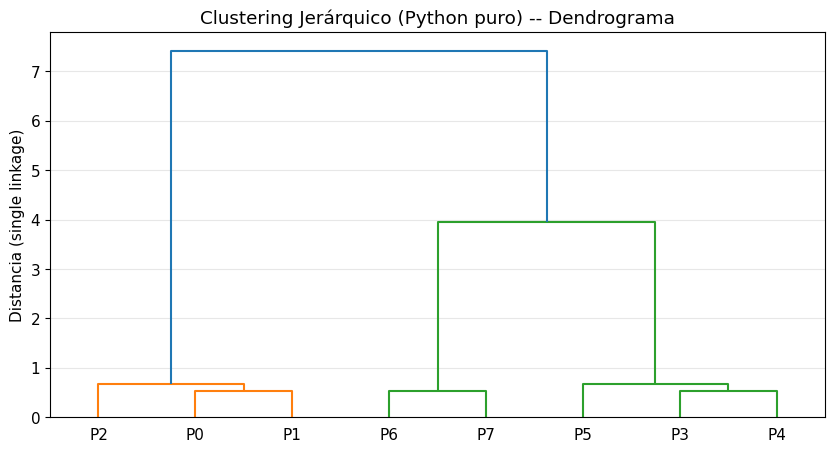

In [11]:
# === GRÁFICA: dendrograma ===
Z = linkage(X_hier, method='single')

fig, ax = plt.subplots(figsize=(10, 5))
dendrogram(Z, labels=labels_init, ax=ax, leaf_font_size=11)
ax.set_title('Clustering Jerárquico (Python puro) -- Dendrograma')
ax.set_ylabel('Distancia (single linkage)')
ax.grid(alpha=0.3, axis='y')
plt.show()


# [SK] 2.6 Clustering Jerárquico -- scikit-learn

## Contexto del ejemplo

Mismo dataset Iris. Veremos cómo el clustering jerárquico con linkage 'average' recupera las especies y compararemos con K-Means.

## Qué aprenderán

- A usar `AgglomerativeClustering` de sklearn.
- A cortar el dendrograma a la altura deseada para obtener K clusters.
- Que el linkage 'average' suele ser más robusto que 'single' (que sufre de "chaining effect").


In [24]:
# === 2.6 CLUSTERING JERÁRQUICO -- scikit-learn ===
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data
y_true = iris.target

agg = AgglomerativeClustering(n_clusters=3, linkage='average')
labels = agg.fit_predict(X)

print(f"ARI vs etiquetas reales: {adjusted_rand_score(y_true, labels):.3f}")
print(f"Silhouette: {silhouette_score(X, labels):.3f}")


ARI vs etiquetas reales: 0.759
Silhouette: 0.554


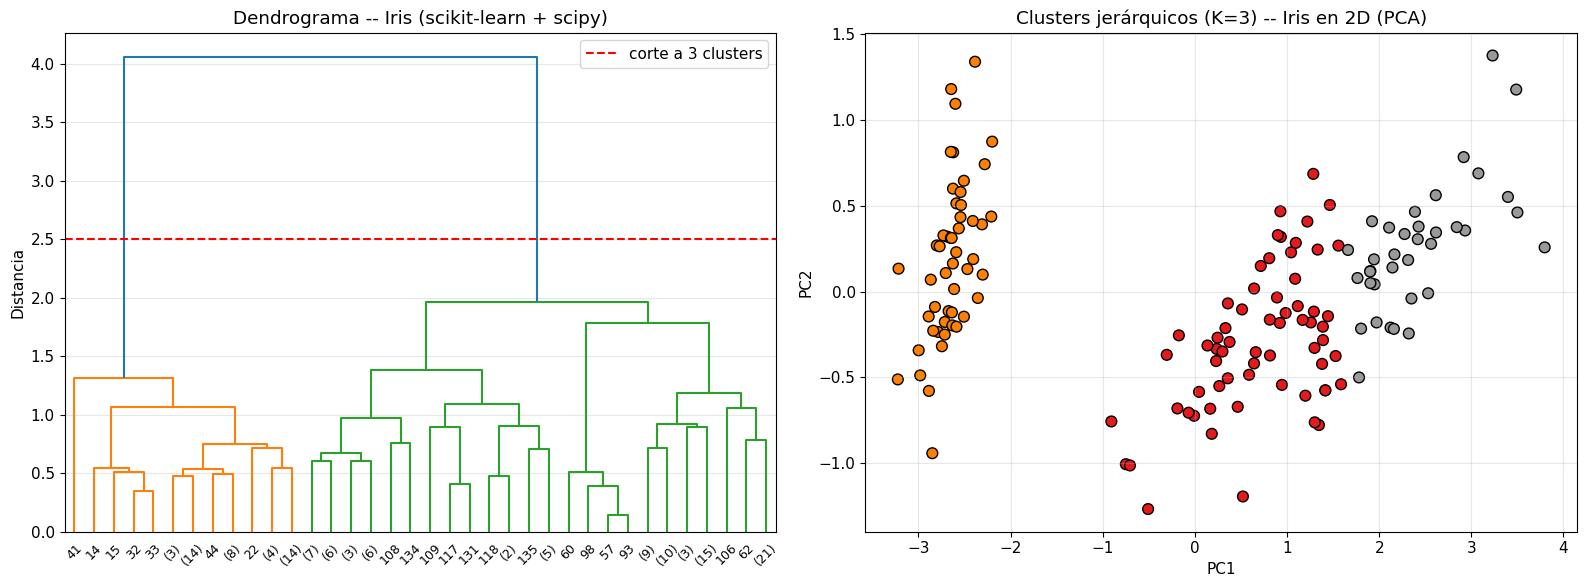

In [13]:
# === GRÁFICA: dendrograma de Iris + visualización 2D ===
# sklearn no expone el dendrograma directo; lo hacemos vía linkage matrix
Z = linkage(X, method='average')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
dendrogram(Z, truncate_mode='level', p=5, ax=ax1, leaf_font_size=9)
ax1.set_title('Dendrograma -- Iris (scikit-learn + scipy)')
ax1.set_ylabel('Distancia')
ax1.axhline(2.5, color='red', ls='--', label='corte a 3 clusters')
ax1.legend(); ax1.grid(alpha=0.3, axis='y')

# Visualización 2D
X_2d = SkPCA(n_components=2).fit_transform(X)
ax2.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='Set1', s=60, edgecolors='k')
ax2.set_title('Clusters jerárquicos (K=3) -- Iris en 2D (PCA)')
ax2.set_xlabel('PC1'); ax2.set_ylabel('PC2'); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()


# [PY] 2.7 DBSCAN -- Python puro

## Contexto del ejemplo

Supongan que tienen datos de localización GPS de clientes y notan que forman dos medialunas entrelazadas. K-Means no puede separarlas (requiere clusters convexos), pero DBSCAN sí, porque se basa en densidad.

## Qué aprenderán

- El concepto de **densidad**: un punto es "núcleo" si tiene al menos `min_pts` vecinos dentro de un radio `eps`.
- La diferencia entre puntos **núcleo**, **frontera** y **ruido**.
- Que DBSCAN **no requiere especificar K** y detecta outliers automáticamente.

## Idea matemática

Para cada punto $p$:
- Si $|N_\epsilon(p)| \geq \text{min\_pts}$ => $p$ es núcleo.
- Un punto $q$ es alcanzable por densidad desde $p$ si hay una cadena de puntos núcleo que los conecta.
- Los puntos no alcanzables desde ningún núcleo son **ruido**.


In [14]:
# === 2.7 DBSCAN -- Python puro ===
np.random.seed(7)
# Generar dos medialunas (moons) sin sklearn
def make_moons(n=100, noise=0.1):
    n_half = n // 2
    t1 = np.linspace(0, np.pi, n_half)
    t2 = np.linspace(0, np.pi, n_half)
    X1 = np.c_[np.cos(t1), np.sin(t1)] + np.random.randn(n_half, 2) * noise
    X2 = np.c_[1 - np.cos(t2), -np.sin(t2) - 0.5] + np.random.randn(n_half, 2) * noise
    return np.vstack([X1, X2])

X_db = make_moons(200, noise=0.08)

def dbscan(X, eps=0.2, min_pts=5):
    n = len(X)
    labels = np.full(n, -1)  # -1 = ruido
    cluster_id = 0
    visited = np.zeros(n, dtype=bool)
    def neighbors(i):
        return np.where(np.linalg.norm(X - X[i], axis=1) <= eps)[0]
    for i in range(n):
        if visited[i]: continue
        visited[i] = True
        nb = neighbors(i)
        if len(nb) < min_pts:
            labels[i] = -1  # ruido
        else:
            cluster_id += 1
            labels[i] = cluster_id
            # Expandir cluster
            queue = list(nb[nb != i])
            while queue:
                j = queue.pop(0)
                if not visited[j]:
                    visited[j] = True
                    nb_j = neighbors(j)
                    if len(nb_j) >= min_pts:
                        queue.extend(nb_j[~visited[nb_j]].tolist())
                if labels[j] == -1:
                    labels[j] = cluster_id
    return labels

labels_db = dbscan(X_db, eps=0.2, min_pts=5)
n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise = (labels_db == -1).sum()
print(f"Clusters encontrados: {n_clusters} | Puntos de ruido: {n_noise}")


Clusters encontrados: 2 | Puntos de ruido: 1


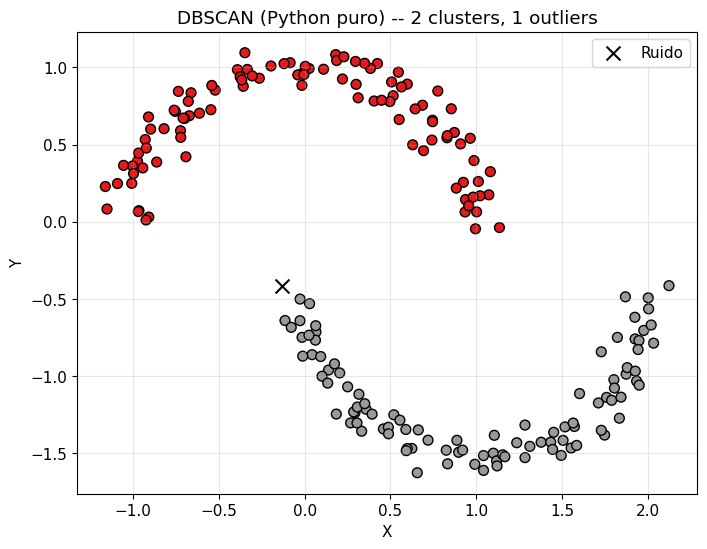

In [15]:
# === GRÁFICA: resultado DBSCAN ===
fig, ax = plt.subplots(figsize=(8, 6))
mask_noise = labels_db == -1
mask_pts = labels_db != -1
ax.scatter(X_db[mask_pts, 0], X_db[mask_pts, 1], c=labels_db[mask_pts], cmap='Set1', s=50, edgecolors='k')
ax.scatter(X_db[mask_noise, 0], X_db[mask_noise, 1], c='black', marker='x', s=100, label='Ruido')
ax.set_title(f'DBSCAN (Python puro) -- {n_clusters} clusters, {n_noise} outliers')
ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.legend(); ax.grid(alpha=0.3)
plt.show()


# [SK] 2.8 DBSCAN -- scikit-learn

## Contexto del ejemplo

Mismo dataset Iris. Veremos que DBSCAN detecta outliers (algo que K-Means no puede hacer) y cómo difieren los resultados al cambiar `eps`.

## Qué aprenderán

- Que DBSCAN es **sensible a la escala**: por eso conviene normalizar antes.
- Que elegir `eps` y `min_samples` requiere inspeccionar los datos.
- A comparar visualmente DBSCAN vs K-Means sobre el mismo dataset.


In [16]:
# === 2.8 DBSCAN -- scikit-learn ===
from sklearn.cluster import DBSCAN
from sklearn.datasets import load_iris

iris = load_iris()
X = StandardScaler().fit_transform(iris.data)  # DBSCAN es sensible a escala
y_true = iris.target

db = DBSCAN(eps=0.7, min_samples=5)
labels = db.fit_predict(X)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = (labels == -1).sum()
print(f"Clusters: {n_clusters} | Ruido: {n_noise} puntos")
# Para ARI solo comparamos puntos que NO son ruido
mask = labels != -1
if mask.sum() > 0:
    print(f"ARI vs etiquetas reales (solo puntos no-ruido): {adjusted_rand_score(y_true[mask], labels[mask]):.3f}")


Clusters: 2 | Ruido: 6 puntos
ARI vs etiquetas reales (solo puntos no-ruido): 0.569


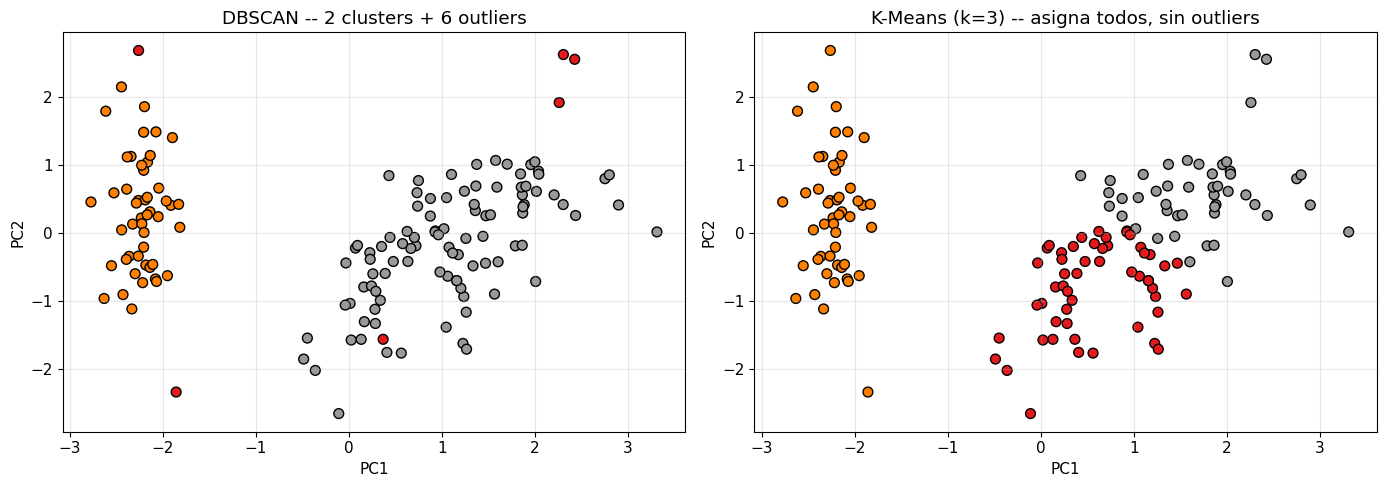

In [17]:
# === GRÁFICA: DBSCAN vs K-Means en Iris (2D) ===
from sklearn.cluster import KMeans

X_2d = SkPCA(n_components=2).fit_transform(X)
km_labels = KMeans(3, random_state=42, n_init=10).fit_predict(X)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
# DBSCAN
scatter1 = ax1.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='Set1', s=50, edgecolors='k')
ax1.set_title(f'DBSCAN -- {n_clusters} clusters + {n_noise} outliers')
ax1.set_xlabel('PC1'); ax1.set_ylabel('PC2'); ax1.grid(alpha=0.3)
# K-Means
ax2.scatter(X_2d[:, 0], X_2d[:, 1], c=km_labels, cmap='Set1', s=50, edgecolors='k')
ax2.set_title('K-Means (k=3) -- asigna todos, sin outliers')
ax2.set_xlabel('PC1'); ax2.set_ylabel('PC2'); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()


# [PY] 2.9 Gaussian Mixture Model (GMM) -- Python puro

## Contexto del ejemplo

A diferencia de K-Means (que asigna cada punto a un solo cluster), GMM asume que los datos provienen de una mezcla de gaussianas y da **probabilidades suaves** de pertenencia. Útil cuando los clusters son elongados (no esféricos) o se solapan.

## Qué aprenderán

- El algoritmo **EM (Expectation-Maximization)**: alterna entre calcular responsabilidades (E-step) y actualizar parámetros (M-step).
- Que GMM modela no solo la media, sino también la **covarianza** de cada cluster (permite elipsoides).
- La noción de **responsabilidad** $r_{ik}$: probabilidad suave de que el punto $i$ pertenezca al cluster $k$.


In [18]:
# === 2.9 GMM con EM -- Python puro ===
np.random.seed(42)
# 2 clusters elongados
c1 = np.random.randn(80, 2) @ np.array([[0.5, 0], [2, 0.5]]) + [2, 2]
c2 = np.random.randn(80, 2) @ np.array([[0.4, 0], [1.5, 0.4]]) + [8, 6]
X_gmm = np.vstack([c1, c2])

def gmm_em(X, K, n_iters=50, seed=42):
    rng = np.random.RandomState(seed)
    n, d = X.shape
    # Inicialización
    means = X[rng.choice(n, K, replace=False)]
    covs = np.array([np.eye(d) for _ in range(K)])
    weights = np.ones(K) / K
    history_means = [means.copy()]

    for _ in range(n_iters):
        # E-step: responsabilidades
        R = np.zeros((n, K))
        for k in range(K):
            R[:, k] = weights[k] * multivariate_normal.pdf(X, means[k], covs[k])
        R = R / R.sum(axis=1, keepdims=True)
        # M-step
        Nk = R.sum(axis=0)
        for k in range(K):
            means[k] = (R[:, k] @ X) / Nk[k]
            diff = X - means[k]
            covs[k] = (R[:, k:k+1] * diff).T @ diff / Nk[k]
            weights[k] = Nk[k] / n
        history_means.append(means.copy())
    return means, covs, weights, history_means, R

means, covs, weights, means_hist, R = gmm_em(X_gmm, K=2, n_iters=30)
print(f"Medias finales: {means.round(2)}")
print(f"Pesos: {weights.round(3)}")
labels_gmm = np.argmax(R, axis=1)


Medias finales: [[8.14 6.02]
 [1.92 2.  ]]
Pesos: [0.5 0.5]


In [19]:
# === GRÁFICA: animación EM + elipsoides ===
fig, ax = plt.subplots(figsize=(9, 6))

def draw_ellipse(mean, cov, color):
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    for nsig in (1, 2):
        w, h = 2 * nsig * np.sqrt(vals)
        ax.add_patch(Ellipse(xy=mean, width=w, height=h, angle=angle,
                             facecolor=color, alpha=0.15, edgecolor=color))

def update(frame):
    ax.clear()
    m = means_hist[min(frame, len(means_hist)-1)]
    if frame > 0:
        ax.scatter(X_gmm[:, 0], X_gmm[:, 1], c=labels_gmm, cmap='Set1', alpha=0.5, s=30)
        draw_ellipse(m[0], covs[0], 'C0')
        draw_ellipse(m[1], covs[1], 'C1')
    ax.scatter(m[:, 0], m[:, 1], c=['C0', 'C1'], marker='X', s=200, edgecolors='k')
    ax.set_title(f'GMM -- iteración EM {frame}')
    ax.set_xlim(-2, 12); ax.set_ylim(-4, 10); ax.grid(alpha=0.3)

anim = animation.FuncAnimation(fig, update, frames=len(means_hist),
                               interval=200, blit=False, repeat=False)
plt.close()
HTML(anim.to_jshtml())


# [SK] 2.10 GMM -- scikit-learn

## Contexto del ejemplo

Mismo dataset Iris. GMM puede descubrir más clusters que las 3 especies reales si lo pedimos. Usaremos la métrica **BIC** para elegir el K óptimo.

## Qué aprenderán

- A usar `GaussianMixture` con `covariance_type='full'` (cada cluster tiene su propia matriz de covarianza completa).
- A comparar modelos con **BIC**: menor BIC = mejor balance ajuste/complejidad.
- Que GMM da probabilidades suaves de pertenencia (no asignaciones duras).


In [20]:
# === 2.10 GMM -- scikit-learn ===
from sklearn.mixture import GaussianMixture
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data
y_true = iris.target

gmm = GaussianMixture(n_components=3, random_state=42, covariance_type='full')
labels = gmm.fit_predict(X)

print(f"Log-likelihood: {gmm.score(X):.3f}")
print(f"Pesos: {gmm.weights_.round(3)}")
print(f"Convergió en {gmm.n_iter_} iteraciones")
print(f"ARI vs etiquetas reales: {adjusted_rand_score(y_true, labels):.3f}")

# Comparar con BIC para distintos K
bic_scores = [GaussianMixture(n_components=k, random_state=42).fit(X).bic(X) for k in range(1, 8)]
best_k = np.argmin(bic_scores) + 1
print(f"BIC óptimo: K={best_k} (BIC={min(bic_scores):.1f})")


Log-likelihood: -1.201
Pesos: [0.365 0.333 0.301]
Convergió en 17 iteraciones
ARI vs etiquetas reales: 0.904
BIC óptimo: K=2 (BIC=574.0)


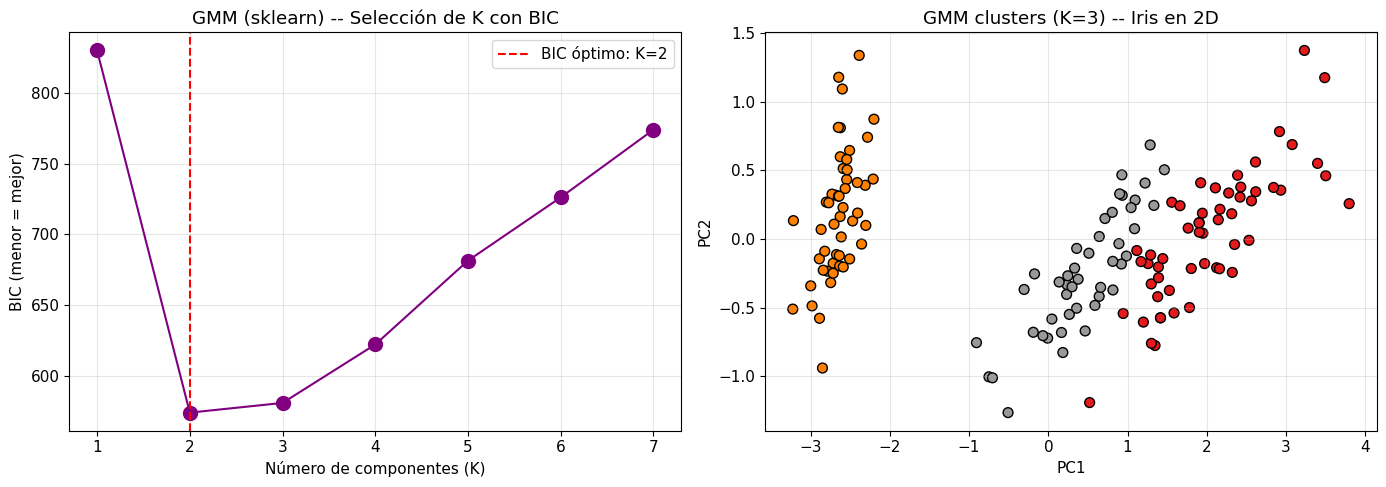

In [21]:
# === GRÁFICA: BIC vs K + clustering 2D ===
X_2d = SkPCA(n_components=2).fit_transform(X)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(range(1, 8), bic_scores, 'o-', color='purple', markersize=10)
ax1.axvline(best_k, color='red', ls='--', label=f'BIC óptimo: K={best_k}')
ax1.set_xlabel('Número de componentes (K)'); ax1.set_ylabel('BIC (menor = mejor)')
ax1.set_title('GMM (sklearn) -- Selección de K con BIC'); ax1.legend(); ax1.grid(alpha=0.3)

ax2.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='Set1', s=50, edgecolors='k')
ax2.set_title(f'GMM clusters (K=3) -- Iris en 2D')
ax2.set_xlabel('PC1'); ax2.set_ylabel('PC2'); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()


# Resumen

## Lo que cubrimos en los ejemplos

| # | Algoritmo | Python puro | scikit-learn |
|---|-----------|:-----------:|:------------:|
| 1 | K-Means | sí | sí (Iris) |
| 2 | PCA | sí | sí (Digits) |
| 3 | Clustering Jerárquico | sí | sí (Iris) |
| 4 | DBSCAN | sí | sí (Iris) |
| 5 | GMM | sí | sí (Iris) |

## Métricas y conceptos vistos

- **Clustering**: Inercia (SSE), Silhouette, ARI
- **Reducción de dimensionalidad**: varianza explicada
- **Modelos probabilísticos**: log-likelihood, BIC
- **Conceptos**: linkage, dendrograma, punto núcleo/frontera/ruido

## Reflexiones

1. **Python puro vs scikit-learn**: implementar a mano ayuda a entender la intuición matemática; scikit-learn ahorra tiempo en producción.
2. **Elección de algoritmo**: no existe uno universal.
   - Si necesitan clusters esféricos y conocen K: K-Means.
   - Si no conocen el número de clusters o hay ruido: DBSCAN.
   - Si los clusters pueden ser elipsoidales: GMM.
   - Si quieren visualizar datos de alta dimensión: PCA.
3. **Visualización**: las gráficas interactivas (Plotly) y animaciones revelan dinámicas que un número solo no muestra (convergencia de centroides, evolución de EM, etc.).

## Próximos pasos sugeridos

- Deben estudiar **t-SNE** y **UMAP** como alternativas no lineales a PCA.
- Profundizar en **HDBSCAN** como mejora de DBSCAN que elige `eps` automáticamente.


---

*Cuaderno generado para fines educativos.*
